In [38]:
import pandas as pd
import requests
from bs4 import BeautifulSoup


In [39]:
url = ("https://www.football-data.co.uk/spainm.php")

response = requests.get(url)

if response.status_code == 200:
    print("data retrived successfully")
else:
    print("Eroor extracting data! please try again!")

data retrived successfully


In [40]:
soup = BeautifulSoup(response.text, 'html.parser')

In [41]:
soup

<html>
<head>
<title>Spain Football Results and Betting Odds</title>
<meta content="Spanish football results, fixed odds, total goals and Asian Handicap betting odds data" name="description"/>
<meta content="Spain, Spansih Football Results, Betting Odds, La Liga" name="keywords"/>
<meta content="7" name="revisit-after"/>
<meta content="Joesph Buchdahl" http-equiv="author"/>
<meta content="Global" name="distribution"/>
<meta content="FOLLOW,INDEX" name="robots"/>
<link href="style.css" rel="stylesheet"/>
</head>
<body alink="#6666CC" bgcolor="#FFFFFF" link="#6666CC" text="#000000" vlink="#6666CC">
<!-- Place this render call where appropriate -->
<script type="text/javascript">
  window.___gcfg = {lang: 'en-GB'};

  (function() {
    var po = document.createElement('script'); po.type = 'text/javascript'; po.async = true;
    po.src = 'https://apis.google.com/js/plusone.js';
    var s = document.getElementsByTagName('script')[0]; s.parentNode.insertBefore(po, s);
  })();
</script>
<table

In [42]:
soup.find_all('a')

[<a href="https://football-data.co.uk/"><img alt="Football Betting - Football Results - Free Bets" border="0" src="https://football-data.co.uk/logo2.jpg"/></a>,
 <a href="https://valuebetfactory.com/?utm_source=football-data&amp;utm_medium=display&amp;utm_campaign=odds-drop-2026-10&amp;utm_content=black-red-468x60" target="_blank"><img alt="ValueBetFactory" border="0" height="60" src="https://football-data.co.uk/banners/vbf_redblack_468x60.gif" width="468"/></a>,
 <a href="https://football-data.co.uk/disclaimer.php"><img alt="legal disclaimer" border="0" height="19" src="https://football-data.co.uk/banner/18.gif" valign="middle" width="19"/></a>,
 <a href="https://www.gambleaware.org/" target="_blank" title="GambleAware"><img alt="GambleAware" border="0" height="12" src="https://football-data.co.uk/banner/gambleaware.jpg" valign="middle"/></a>,
 <a href="https://twitter.com/12Xpert" target="blank" title="Follow me on X"><img alt="Twitter" border="0" height="19" src="https://football-da

In [43]:
for a in soup.find_all('a'):
    if 'SP1.csv' in a ['href']:
        print(a['href'])



mmz4281/2627/SP1.csv
mmz4281/2526/SP1.csv
mmz4281/2425/SP1.csv
mmz4281/2324/SP1.csv
mmz4281/2223/SP1.csv
mmz4281/2122/SP1.csv
mmz4281/2021/SP1.csv
mmz4281/1920/SP1.csv
mmz4281/1819/SP1.csv
mmz4281/1718/SP1.csv
mmz4281/1617/SP1.csv
mmz4281/1516/SP1.csv
mmz4281/1415/SP1.csv
mmz4281/1314/SP1.csv
mmz4281/1213/SP1.csv
mmz4281/1112/SP1.csv
mmz4281/1011/SP1.csv
mmz4281/0910/SP1.csv
mmz4281/0809/SP1.csv
mmz4281/0708/SP1.csv
mmz4281/0607/SP1.csv
mmz4281/0506/SP1.csv
mmz4281/0405/SP1.csv
mmz4281/0304/SP1.csv
mmz4281/0203/SP1.csv
mmz4281/0102/SP1.csv
mmz4281/0001/SP1.csv
mmz4281/9900/SP1.csv
mmz4281/9899/SP1.csv
mmz4281/9798/SP1.csv
mmz4281/9697/SP1.csv
mmz4281/9596/SP1.csv
mmz4281/9495/SP1.csv
mmz4281/9394/SP1.csv


In [44]:
lenker = []

for a in soup.find_all('a'):
    if 'SP1.csv' in a ['href']:
        år = a['href'].split('/')[1]
        if int(år) >= 1516 and int(år) <= 2526:
            lenker.append(a['href'])

print(lenker)

['mmz4281/2526/SP1.csv', 'mmz4281/2425/SP1.csv', 'mmz4281/2324/SP1.csv', 'mmz4281/2223/SP1.csv', 'mmz4281/2122/SP1.csv', 'mmz4281/2021/SP1.csv', 'mmz4281/1920/SP1.csv', 'mmz4281/1819/SP1.csv', 'mmz4281/1718/SP1.csv', 'mmz4281/1617/SP1.csv', 'mmz4281/1516/SP1.csv']


In [45]:
base_url = 'https://www.football-data.co.uk/'

full_url = base_url + lenker[0]
full_url

'https://www.football-data.co.uk/mmz4281/2526/SP1.csv'

In [46]:
rådata = {}

for lenke in lenker:
    full_url = base_url + lenke
    response = requests.get(full_url)

    sesong = lenke.split('/')[1]

    if response.status_code == 200:
        response.encoding = 'utf-8-sig'
        rådata[sesong] = response.text
    else:
        print('Feil for sesong', sesong, response.status_code)
print('Sesonger hentet:', list(rådata.keys()))
print('Antall:', len(rådata))
   

Sesonger hentet: ['2526', '2425', '2324', '2223', '2122', '2021', '1920', '1819', '1718', '1617', '1516']
Antall: 11


In [47]:
print(rådata['2425'][:600])

Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,BWH,BWD,BWA,BFH,BFD,BFA,PSH,PSD,PSA,WHH,WHD,WHA,1XBH,1XBD,1XBA,MaxH,MaxD,MaxA,AvgH,AvgD,AvgA,BFEH,BFED,BFEA,B365>2.5,B365<2.5,P>2.5,P<2.5,Max>2.5,Max<2.5,Avg>2.5,Avg<2.5,BFE>2.5,BFE<2.5,AHh,B365AHH,B365AHA,PAHH,PAHA,MaxAHH,MaxAHA,AvgAHH,AvgAHA,BFEAHH,BFEAHA,B365CH,B365CD,B365CA,BWCH,BWCD,BWCA,BFCH,BFCD,BFCA,PSCH,PSCD,PSCA,WHCH,WHCD,WHCA,1XBCH,1XBCD,1XBCA,MaxCH,MaxCD,MaxCA,AvgCH,AvgCD,AvgCA,BFECH,BFECD,BFECA,B365C>2.5,B365C<2.5,PC>2.5,PC<2.5,MaxC>2.5,MaxC<2.5,AvgC>2.5,AvgC<2.5,BFE


In [48]:
tekst = rådata['2425']

linjer = tekst.strip().splitlines()
header = linjer[0].split(',')

print('Antall linjer:', len(linjer))
print('Antall kolonner:', len(header))
print('\nDe første 23 kolonnene:')
print(header[:23])
print('\nFørste kamp:')
print(linjer[1][:150])

Antall linjer: 381
Antall kolonner: 119

De første 23 kolonnene:
['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']

Første kamp:
SP1,15/08/2024,18:00,Ath Bilbao,Getafe,1,1,D,1,0,H,7,9,4,2,15,12,5,6,4,1,0,0,1.48,4,8,1.44,4.2,7.75,1.53,3.9,7.5,1.48,4.12,8.24,1.44,4,8.5,1.52,4.16,8


In [49]:
ønskede_kolonner = ['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']

indekser = {}
for kolonne in ønskede_kolonner:
    indekser[kolonne] = header.index(kolonne)

print(indekser)


{'Date': 1, 'HomeTeam': 3, 'AwayTeam': 4, 'FTHG': 5, 'FTAG': 6, 'FTR': 7, 'HTHG': 8, 'HTAG': 9, 'HTR': 10, 'HS': 11, 'AS': 12, 'HST': 13, 'AST': 14, 'HF': 15, 'AF': 16, 'HC': 17, 'AC': 18, 'HY': 19, 'AY': 20, 'HR': 21, 'AR': 22}


In [50]:
celler = linjer[1].split(',')

første_kamp = {}
for kolonne, indeks in indekser.items():
    første_kamp[kolonne] = celler[indeks]
print(første_kamp)

{'Date': '15/08/2024', 'HomeTeam': 'Ath Bilbao', 'AwayTeam': 'Getafe', 'FTHG': '1', 'FTAG': '1', 'FTR': 'D', 'HTHG': '1', 'HTAG': '0', 'HTR': 'H', 'HS': '7', 'AS': '9', 'HST': '4', 'AST': '2', 'HF': '15', 'AF': '12', 'HC': '5', 'AC': '6', 'HY': '4', 'AY': '1', 'HR': '0', 'AR': '0'}


In [51]:
for sesong, tekst in rådata.items():
    h = tekst.strip().splitlines()[0].split(',')
    mangler = []
    for kolonne in ønskede_kolonner:
        if kolonne not in h:
            mangler.append(kolonne)
    print(sesong, 'mangler:', mangler)

2526 mangler: []
2425 mangler: []
2324 mangler: []
2223 mangler: []
2122 mangler: []
2021 mangler: []
1920 mangler: []
1819 mangler: []
1718 mangler: []
1617 mangler: []
1516 mangler: []


In [52]:
from datetime import datetime

def konverter_dato(tekst):
    tekst = tekst.strip()
    for datoformat in ('%d/%m/%Y','%d/%m/%y'):
        try:
            return datetime.strptime(tekst, datoformat)
        except ValueError:
            pass
    return None


def konverter_int(tekst):
    tekst = tekst.strip()
    if tekst == '':
        return None
    try:
        return int(float(tekst))
    except ValueError:
        return None

In [53]:
print(konverter_dato('15/08/2024'))   # nytt format
print(konverter_dato('18/08/17'))     # gammelt format
print(konverter_dato('tull'))         # ugyldig -> None
print(konverter_int('3'))
print(konverter_int(''))              # tom -> None


2024-08-15 00:00:00
2017-08-18 00:00:00
None
3
None


In [54]:
def rad_er_gyldig(rad):
    if rad['Date'] is None:
        return False
    if rad['FTR'] not in ['H', 'D', 'A']:
        return False
    if rad['HomeTeam'] == '' or rad['AwayTeam'] == '':
        return False
    return True


In [55]:
tall_kolonner = ['FTHG', 'FTAG', 'HTHG', 'HTAG', 'HS', 'AS', 'HST', 'AST',
                 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']

rensede_rader = []
forkastet = 0

for sesong, tekst in rådata.items():
    linjer = tekst.strip().splitlines()
    h = linjer[0].split(',')

    indekser = {}
    for kolonne in ønskede_kolonner:
        indekser[kolonne] = h.index(kolonne)
    høyeste = max(indekser.values())

    for linje in linjer[1:]:
        celler = linje.split(',')

        if len(celler) <= høyeste:
            forkastet += 1
            continue

        rad = {'Sesong' : sesong}
        for kolonne, indeks in indekser.items():
            verdi = celler[indeks]
            if kolonne == 'Date':
                rad[kolonne] = konverter_dato(verdi)
            elif kolonne in tall_kolonner:
                rad[kolonne] = konverter_int(verdi)
            else:
                rad[kolonne] = verdi.strip()


        if rad_er_gyldig(rad):
            rensede_rader.append(rad)
        else:
            forkastet += 1

print('Gyldige kamper:', len(rensede_rader))
print('Forkastet:', forkastet)
print('\nFørste rad:')
print(rensede_rader[0])

Gyldige kamper: 4180
Forkastet: 0

Første rad:
{'Sesong': '2526', 'Date': datetime.datetime(2025, 8, 15, 0, 0), 'HomeTeam': 'Girona', 'AwayTeam': 'Vallecano', 'FTHG': 1, 'FTAG': 3, 'FTR': 'A', 'HTHG': 0, 'HTAG': 3, 'HTR': 'A', 'HS': 7, 'AS': 16, 'HST': 2, 'AST': 5, 'HF': 8, 'AF': 17, 'HC': 2, 'AC': 4, 'HY': 0, 'AY': 1, 'HR': 1, 'AR': 0}


In [56]:
import pandas as pd

df = pd.DataFrame(rensede_rader)
df = df.sort_values('Date').reset_index(drop=True)

print('Form:', df.shape)
print()
print(df.dtypes)
df.head()

Form: (4180, 22)

Sesong              object
Date        datetime64[ns]
HomeTeam            object
AwayTeam            object
FTHG                 int64
FTAG                 int64
FTR                 object
HTHG                 int64
HTAG                 int64
HTR                 object
HS                   int64
AS                   int64
HST                  int64
AST                  int64
HF                   int64
AF                   int64
HC                   int64
AC                   int64
HY                   int64
AY                   int64
HR                   int64
AR                   int64
dtype: object


,Sesong,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,1516,2015-08-21,Malaga,Sevilla,0,0,D,0,0,D,...,5,2,19,11,7,2,3,3,0,1
1,1516,2015-08-22,La Coruna,Sociedad,0,0,D,0,0,D,...,5,2,16,10,5,4,3,2,0,0
2,1516,2015-08-22,Espanol,Getafe,1,0,H,1,0,H,...,2,3,19,14,5,6,2,3,0,1
3,1516,2015-08-22,Vallecano,Valencia,0,0,D,0,0,D,...,3,4,19,11,3,3,3,1,0,0
4,1516,2015-08-22,Ath Madrid,Las Palmas,1,0,H,1,0,H,...,3,1,11,16,4,4,2,0,0,0


In [57]:
print(df.isnull().sum())

Sesong      0
Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64


In [58]:
print(df['Sesong'].value_counts().sort_index())
print()
print(df.groupby('Sesong')['HomeTeam'].nunique())


Sesong
1516    380
1617    380
1718    380
1819    380
1920    380
2021    380
2122    380
2223    380
2324    380
2425    380
2526    380
Name: count, dtype: int64

Sesong
1516    20
1617    20
1718    20
1819    20
1920    20
2021    20
2122    20
2223    20
2324    20
2425    20
2526    20
Name: HomeTeam, dtype: int64


In [59]:
lag = sorted(df['HomeTeam'].unique())
print(len(lag), 'forskjellige lag:')
print(lag)

31 forskjellige lag:
['Alaves', 'Almeria', 'Ath Bilbao', 'Ath Madrid', 'Barcelona', 'Betis', 'Cadiz', 'Celta', 'Eibar', 'Elche', 'Espanol', 'Getafe', 'Girona', 'Granada', 'Huesca', 'La Coruna', 'Las Palmas', 'Leganes', 'Levante', 'Malaga', 'Mallorca', 'Osasuna', 'Oviedo', 'Real Madrid', 'Sevilla', 'Sociedad', 'Sp Gijon', 'Valencia', 'Valladolid', 'Vallecano', 'Villarreal']


In [60]:
df.to_csv('la_liga_renset.csv', index=False)
print('Lagret!')

Lagret!


FTR
H    1912
A    1180
D    1088
Name: count, dtype: int64

FTR
H    45.7
A    28.2
D    26.0
Name: proportion, dtype: float64


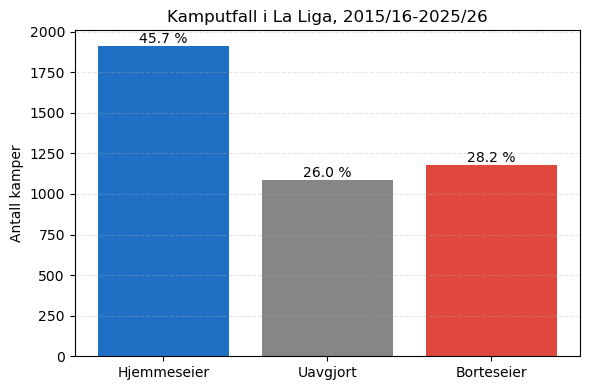

In [61]:
import matplotlib.pyplot as plt

FARGER = { 'H': '#1f6fc5', 'D': '#868686', 'A':'#e0483e'}
NAVN = {'H': 'Hjemmeseier', 'D': 'Uavgjort', 'A': 'Borteseier'}

antall = df['FTR'].value_counts()
andel = df['FTR'].value_counts(normalize=True) * 100

print(antall)
print()
print(andel.round(1))

etiketter = [f"{andel['H']:.1f} %", f"{andel['D']:.1f} %", f"{andel['A']:.1f} %"]

plt.figure(figsize=(6,4))
søyler = plt.bar([NAVN['H'], NAVN['D'], NAVN['A']], [antall['H'], antall['D'], antall['A']], color=[FARGER['H'], FARGER['D'], FARGER['A']])

plt.bar_label(søyler, labels=etiketter)
plt.title('Kamputfall i La Liga, 2015/16-2025/26')
plt.ylabel('Antall kamper')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


FTR        A     D     H
Sesong                  
1516    27.6  24.2  48.2
1617    28.9  23.4  47.6
1718    30.3  22.6  47.1
1819    26.8  28.9  44.2
1920    26.6  27.6  45.8
2021    29.7  28.7  41.6
2122    27.4  29.2  43.4
2223    28.7  23.4  47.9
2324    27.9  28.2  43.9
2425    30.0  25.5  44.5
2526    26.6  24.5  48.9


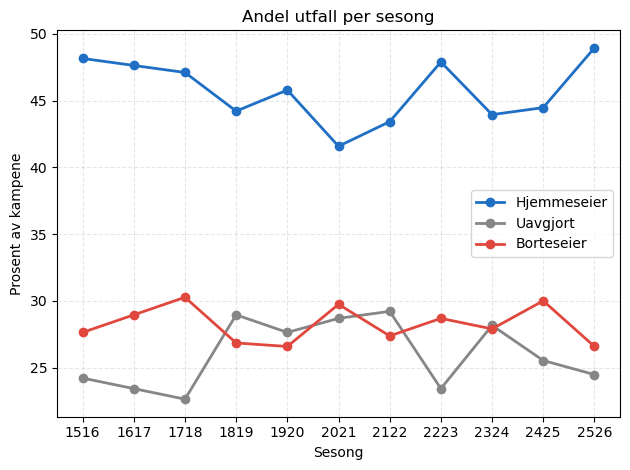

In [62]:
tabell = pd.crosstab(df['Sesong'], df['FTR'], normalize='index') * 100
print(tabell.round(1))

plt.Figure(figsize=(9,4))
for utfall in ['H', 'D', 'A']:
    plt.plot(tabell.index, tabell[utfall], marker='o', linewidth=2,
             color=FARGER[utfall], label=NAVN[utfall])


plt.title('Andel utfall per sesong')
plt.xlabel('Sesong')
plt.ylabel('Prosent av kampene')
plt.legend()
plt.grid(linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
#tester hvordan grafene oppfører seg med og uten publikum
#på grunn av corona og tomme tribuner


uten_publikum = (df['Date'] >= '2020-06-11') & (df['Date'] <= '2021-05-23')

for navn, utvalg in [('Med publikum', df[~uten_publikum]), ('Uten publikum', df[uten_publikum])]:
    fordeling = utvalg['FTR'].value_counts(normalize=True) *100
    print(f"{navn}: {len(utvalg)} kamper | "
          f"H {fordeling['H']:.1f} % D {fordeling['D']:.1f} % A {fordeling['A']:.1f} %")



Med publikum: 3690 kamper | H 46.3 % D 25.7 % A 28.0 %
Uten publikum: 490 kamper | H 41.4 % D 28.4 % A 30.2 %


Snitt mål hjemmelag: 1.5
Snitt mål bortelag: 1.13
Snitt mål per kamp: 2.63
Andel kamper der bortelaget ikke scorer: 32.9 %


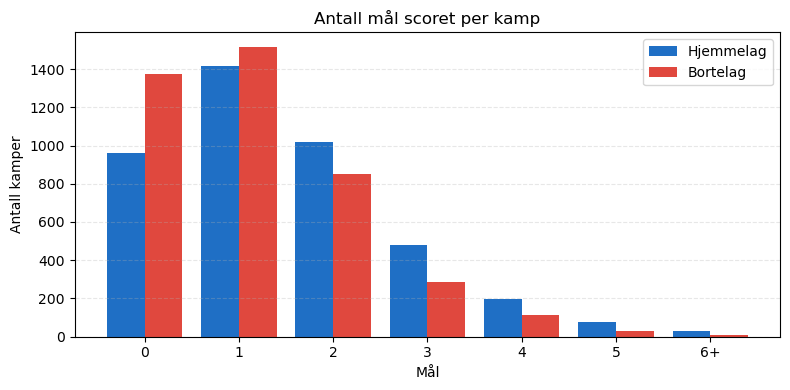

In [64]:
import numpy as np

mål = range(7)
hjemme = df['FTHG'].clip(upper=6).value_counts().reindex(mål, fill_value=0)
borte = df['FTAG'].clip(upper=6).value_counts().reindex(mål, fill_value=0)

print('Snitt mål hjemmelag:', round(df['FTHG'].mean(), 2))
print('Snitt mål bortelag:', round(df['FTAG'].mean(), 2))
print('Snitt mål per kamp:', round((df['FTHG'] + df['FTAG']).mean(), 2))
print('Andel kamper der bortelaget ikke scorer:', round((df['FTAG'] == 0).mean() * 100, 1), '%') 

x = np.arange(len(mål))
bredde = 0.4

plt.figure(figsize=(8, 4))
plt.bar(x - bredde/2, hjemme, width=bredde, color=FARGER['H'], label='Hjemmelag')
plt.bar(x + bredde/2, borte, width=bredde, color=FARGER['A'], label='Bortelag')
plt.xticks(x, ['0', '1', '2', '3', '4', '5', '6+'])
plt.title('Antall mål scoret per kamp')
plt.xlabel('Mål')
plt.ylabel('Antall kamper')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()





             Poeng per kamp  Kamper
Lag                                
Oviedo                 0.76      38
Almeria                0.82      76
Huesca                 0.88      76
Valladolid             0.89     190
Sp Gijon               0.92      76
Las Palmas             0.93     190
La Coruna              0.94     114
Elche                  0.96     152
Granada                0.96     228
Malaga                 1.00     114
Cadiz                  1.04     152
Leganes                1.05     190
Levante                1.09     266
Mallorca               1.11     228
Vallecano              1.13     266
Alaves                 1.14     342
Espanol                1.15     342
Eibar                  1.17     228
Osasuna                1.17     304
Getafe                 1.21     380
Celta                  1.25     418
Girona                 1.32     228
Valencia               1.33     418
Betis                  1.43     418
Ath Bilbao             1.45     418
Sociedad               1.47 

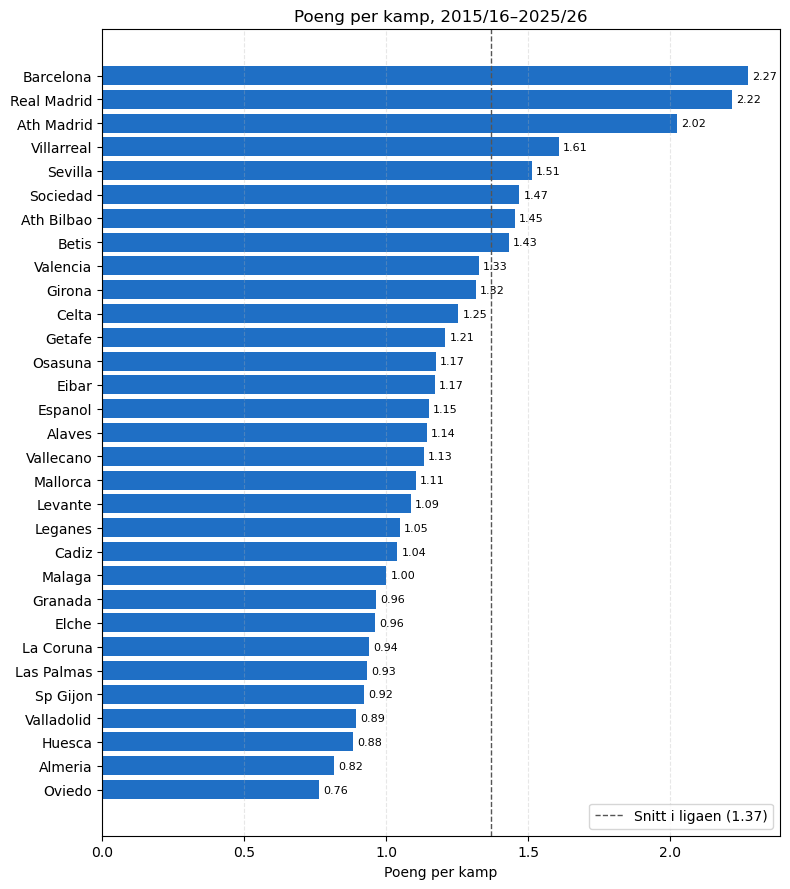

In [65]:
hjemme_poeng = df['FTR'].map({'H': 3, 'D': 1, 'A': 0})
borte_poeng = df['FTR'].map({'H': 0, 'D': 1, 'A': 3})

lagkamper = pd.concat([
    pd.DataFrame({'Lag': df['HomeTeam'], 'Poeng': hjemme_poeng}),
    pd.DataFrame({'Lag': df['AwayTeam'], 'Poeng': borte_poeng})
])

lagstyrke = lagkamper.groupby('Lag')['Poeng'].agg(['mean', 'count'])
lagstyrke.columns = ['Poeng per kamp', 'Kamper']
lagstyrke = lagstyrke.sort_values('Poeng per kamp')
print(lagstyrke.round(2))

snitt = lagkamper['Poeng'].mean()

plt.figure(figsize=(8, 9))
søyler = plt.barh(lagstyrke.index, lagstyrke['Poeng per kamp'], color=FARGER['H'])
plt.bar_label(søyler, fmt='%.2f', padding=3, fontsize=8)
plt.axvline(snitt, color='#555555', linestyle='--', linewidth=1,
            label=f'Snitt i ligaen ({snitt:.2f})')
plt.title('Poeng per kamp, 2015/16–2025/26')
plt.xlabel('Poeng per kamp')
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Korrelasjon med mål:
   Skudd totalt: 0.29
   Skudd på mål: 0.58

Skudd på mål
0     0.06
1     0.38
2     0.70
3     0.96
4     1.28
5     1.54
6     1.81
7     2.19
8     2.52
9     2.82
10    3.00
11    3.28
12    3.67
Name: Mål, dtype: float64


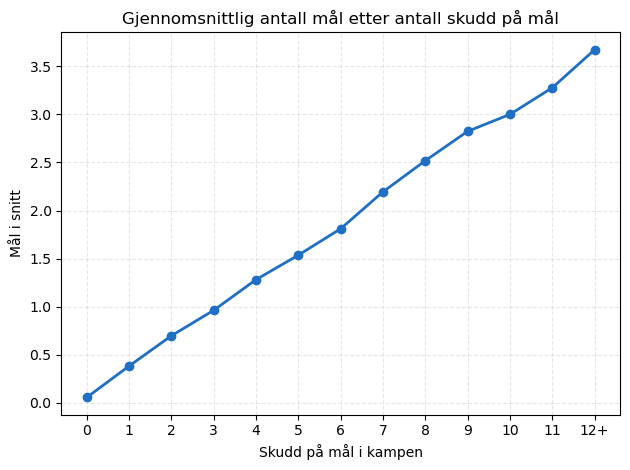

In [66]:
skudd = pd.concat([
    pd.DataFrame({'Skudd': df['HS'], 'Skudd på mål': df['HST'], 'Mål': df['FTHG']}),
    pd.DataFrame({'Skudd': df['AS'], 'Skudd på mål': df['AST'], 'Mål': df['FTAG']}),

])

print('Korrelasjon med mål:')
print('   Skudd totalt:', round(skudd['Skudd'].corr(skudd['Mål']), 2))
print('   Skudd på mål:', round(skudd['Skudd på mål'].corr(skudd['Mål']), 2))

per_skudd = skudd.groupby(skudd['Skudd på mål'].clip(upper=12))['Mål'].mean()
print()
print(per_skudd.round(2))

plt.Figure(figsize=(8,4))
plt.plot(per_skudd.index, per_skudd.values, marker='o', linewidth=2, color=FARGER['H'])
plt.xticks(range(13), [str (i) for i in range(12)] + ['12+'])
plt.title('Gjennomsnittlig antall mål etter antall skudd på mål')
plt.xlabel('Skudd på mål i kampen')
plt.ylabel('Mål i snitt')
plt.grid(linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
hjemmerader = pd.DataFrame({
    'KampID': df.index,
    'Date': df['Date'],
    'Lag': df['HomeTeam'],
    'Hjemme': 1,
    'Poeng': df['FTR'].map({'H': 3, 'D': 1, 'A': 0}),
    'MålFor': df['FTHG'],
    'MålMot': df['FTAG'],
    'SkuddPåMålFor': df['HST'],
    'SkuddPåMålMot': df['AST']
})

borterader = pd.DataFrame({
    'KampID': df.index,
    'Date': df['Date'],
    'Lag': df['AwayTeam'],
    'Hjemme': 0,
    'Poeng': df['FTR'].map({'H': 0, 'D': 1, 'A': 3}),
    'MålFor': df['FTAG'],
    'MålMot': df['FTHG'],
    'SkuddPåMålFor': df['AST'],
    'SkuddPåMålMot': df['HST']
})

lag_df = pd.concat([hjemmerader, borterader])
lag_df = lag_df.sort_values(['Lag', 'Date']).reset_index(drop=True)

print('Form', lag_df.shape)
lag_df[lag_df['Lag'] == 'Barcelona'].head(6)

Form (8360, 9)


,KampID,Date,Lag,Hjemme,Poeng,MålFor,MålMot,SkuddPåMålFor,SkuddPåMålMot
1254,8,2015-08-23,Barcelona,0,3,1,0,4,2
1255,13,2015-08-29,Barcelona,1,3,1,0,13,1
1256,21,2015-09-12,Barcelona,0,3,2,1,5,3
1257,35,2015-09-20,Barcelona,1,3,4,1,8,4
1258,47,2015-09-23,Barcelona,0,0,1,4,7,5
1259,51,2015-09-26,Barcelona,1,3,2,1,6,6


In [68]:
statistikk = ['Poeng', 'MålFor', 'MålMot', 'SkuddPåMålFor', 'SkuddPåMålMot']

for kolonne in statistikk:
    lag_df['Snitt' + kolonne] = (
        lag_df.groupby('Lag')[kolonne]
        .transform(lambda s: s.shift(1).rolling(5, min_periods=5).mean())
    )
lag_df[lag_df['Lag'] == 'Barcelona'][['Date', 'Poeng', 'SnittPoeng', 'MålFor', 'SnittMålFor']].head(8)


,Date,Poeng,SnittPoeng,MålFor,SnittMålFor
1254,2015-08-23,3,NaN,1,NaN
1255,2015-08-29,3,NaN,1,NaN
1256,2015-09-12,3,NaN,2,NaN
1257,2015-09-20,3,NaN,4,NaN
1258,2015-09-23,0,NaN,1,NaN
1259,2015-09-26,3,2.4,2,1.8
1260,2015-10-03,0,2.4,1,2.0
1261,2015-10-17,3,1.8,5,2.0


In [69]:
feature_kolonner = ['SnittPoeng', 'SnittMålFor', 'SnittMålMot', 
                    'SnittSkuddPåMålFor', 'SnittSkuddPåMålMot']

hjemme_features = lag_df[lag_df['Hjemme'] == 1][['KampID'] + feature_kolonner]
borte_features = lag_df[lag_df['Hjemme'] == 0][['KampID'] + feature_kolonner]

hjemme_features = hjemme_features.add_prefix('H_').rename(columns={'H_KampID': 'KampID'})
borte_features  = borte_features.add_prefix('A_').rename(columns={'A_KampID': 'KampID'})

kamper = df.copy()
kamper['KampID'] = kamper.index
kamper = kamper.merge(hjemme_features, on='KampID').merge(borte_features, on='KampID')

print('Før vi fjerner tomme rader:', kamper.shape)
kamper = kamper.dropna().reset_index(drop=True)
print('Etter:', kamper.shape)


Før vi fjerner tomme rader: (4180, 33)
Etter: (4075, 33)


In [70]:
numeriske = ['H_' + k for k in feature_kolonner] + ['A_' + k for k in feature_kolonner]
kategoriske = ['HomeTeam', 'AwayTeam']

test_maske = kamper['Sesong'] == '2526'

X_train = kamper.loc[~test_maske, numeriske + kategoriske]
y_train = kamper.loc[~test_maske, 'FTR']
X_test = kamper.loc[test_maske, numeriske + kategoriske]
y_test = kamper.loc[test_maske, 'FTR']

print('Trening:', X_train.shape)
print('Test:    ', X_test.shape)
print()
print('Baseline på testsetet (alltid gjette hjemmeseier):', round((y_test == 'H').mean() * 100,1), '%')

Trening: (3700, 12)
Test:     (375, 12)

Baseline på testsetet (alltid gjette hjemmeseier): 48.5 %


Accurcay: 50.1 %
Baseline: 48.5 %

              precision    recall  f1-score   support

           A       0.40      0.38      0.39       100
           D       0.23      0.03      0.06        93
           H       0.55      0.81      0.65       182

    accuracy                           0.50       375
   macro avg       0.39      0.41      0.37       375
weighted avg       0.43      0.50      0.44       375



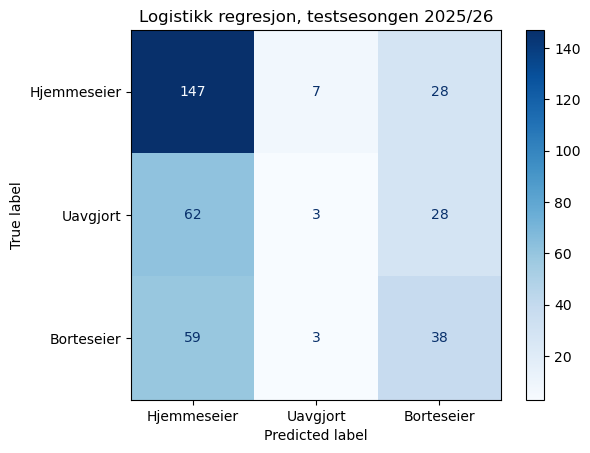

In [71]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay


preprocess = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeriske),
    ('cat', OneHotEncoder(handle_unknown='ignore'), kategoriske)
])

logreg = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])

logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)

print('Accurcay:', round(accuracy_score(y_test, y_pred) * 100, 1), '%')
print('Baseline:', round((y_test == 'H').mean() * 100, 1), '%')

print()
print(classification_report(y_test, y_pred, zero_division=0))


ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=['H', 'D', 'A'],
    display_labels=['Hjemmeseier', 'Uavgjort', 'Borteseier'],
    cmap='Blues'
)

plt.title('Logistikk regresjon, testsesongen 2025/26')
plt.show()

KNN accuracy:    42.1 %
LogReg accuracy: 50.1 %
Baseline:        48.5 %

Hvor ofte KNN gjetter hvert utfall:
H    205
A    111
D     59
Name: count, dtype: int64

              precision    recall  f1-score   support

           A       0.35      0.39      0.37       100
           D       0.22      0.14      0.17        93
           H       0.52      0.58      0.55       182

    accuracy                           0.42       375
   macro avg       0.36      0.37      0.36       375
weighted avg       0.40      0.42      0.41       375



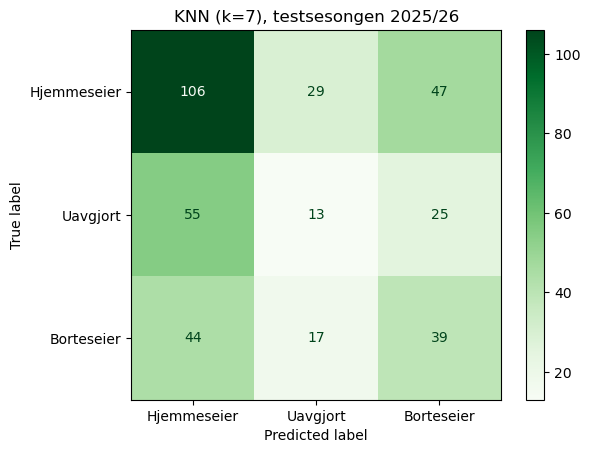

In [72]:
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline(steps=[
    ('preprocess', clone(preprocess)),
    ('model', KNeighborsClassifier(n_neighbors=7, weights='distance', metric='euclidean')),
])

knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

print('KNN accuracy:   ', round(accuracy_score(y_test, y_pred_knn) * 100, 1), '%')
print('LogReg accuracy:', round(accuracy_score(y_test, y_pred) * 100, 1), '%')
print('Baseline:       ', round((y_test == 'H').mean() * 100, 1), '%')
print()
print('Hvor ofte KNN gjetter hvert utfall:')
print(pd.Series(y_pred_knn).value_counts())
print()
print(classification_report(y_test, y_pred_knn, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn,
    labels=['H', 'D', 'A'],
    display_labels=['Hjemmeseier', 'Uavgjort', 'Borteseier'],
    cmap='Greens'
)
plt.title('KNN (k=7), testsesongen 2025/26')
plt.show()